# Actividad 05 - 04. Evaluación y resultados preliminares

**NewCodeCreds** · Edward Alexander Gómez Ispanel, Jocelyn Abigail De León Ardón y Brazil Abraham
Batres Cruz - Maestría en Data Science - Investigación en Data Science - Noviembre 2026

Datos: las predicciones fuera de muestra de Gitleaks y Random Forest (notebook 02) y, si
existen, las de GraphCodeBERT (notebook 03), sobre las líneas candidatas de CredData. Este
notebook calcula las métricas, las diferencias pareadas, las figuras y el CSV de muestra.

**Criterio de evaluación:** el estudio no compara contra un baseline de desempeño mínimo,
sino contra una **condición de referencia**: la partición aleatoria deduplicada, que
representa la evaluación favorable usada en la literatura. La pregunta se responde con la
diferencia de desempeño (F1 y MCC; PR-AUC para los modelos) de cada detector entre esa
referencia y las particiones por organización y por tipo de archivo, calculada sobre las
**mismas líneas** e intervalos de confianza por bootstrap pareado, remuestreando por
organización. Gitleaks funciona como referencia de reglas: no se entrena, así que sus
predicciones no cambian entre particiones.

Si existe `predicciones_graphcodebert.parquet` (notebook 03), se incorpora automáticamente.
GraphCodeBERT se une por la clave de la línea (archivo, LineStart, LineEnd) y no por `id_linea`,
porque su corrida en modo rápido usó la versión anterior de la tabla (ver sección 0).

## 0. Configuración

Umbral de decisión 0.5 para los modelos y 1,000 remuestreos de organizaciones en el bootstrap.
Si existe `predicciones_graphcodebert.parquet`, se agrega GraphCodeBERT. Su corrida en modo
rápido usó la tabla de la versión anterior del notebook 01 (lectura con `splitlines()`),
resumida sin texto en `datos_procesados/graphcodebert_tabla_v1.parquet`, con los mismos pliegues que Random Forest. Se une por clave
de línea y se evalúa solo donde las dos versiones coinciden. Como se entrenó con 20,000 líneas,
1 época y una línea de contexto, la comparación válida es GraphCodeBERT contra sí mismo entre
particiones, no contra Random Forest.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(".")
from ids_utils import REPO_DOMINANTE, bootstrap_pareado, metricas

DATOS = Path("../datos_procesados")
RES = Path("../resultados")
FIG = Path("../figuras")
FIG.mkdir(exist_ok=True)

UMBRAL = 0.5
CLAVE = ["FilePath", "LineStart", "LineEnd"]
p = pd.read_parquet(DATOS / "predicciones.parquet")
detectores = ["rf"]
gcb = DATOS / "predicciones_graphcodebert.parquet"
if gcb.exists():
    g_pred = pd.read_parquet(gcb)
    # Tabla (sin texto) con la que se corrió GraphCodeBERT: clave de la línea, si estaba deduplicada,
    # su etiqueta y si su texto coincide con la lectura actual. Se versiona en el repositorio.
    v1 = pd.read_parquet(DATOS / "graphcodebert_tabla_v1.parquet")
    g_pred = v1.merge(g_pred, on="id_linea").drop(columns="id_linea")
    p = p.merge(g_pred, on=CLAVE, how="left")
    # GraphCodeBERT solo se evalúa donde las dos versiones de la tabla coinciden: línea deduplicada
    # en ambas, misma etiqueta y mismo texto (excluye las líneas que v1 leyó desalineadas).
    igual = p.texto_igual_v1.fillna(False).astype(bool)
    valida = (p.dedup == 1) & (p.dedup_v1 == 1) & (p.y_dedup == p.y_dedup_v1) & igual
    print("GraphCodeBERT | líneas deduplicadas (v2):", int((p.dedup == 1).sum()),
          "| evaluables:", int(valida.sum()),
          "| fuera por no estar deduplicadas en v1:", int(((p.dedup == 1) & (p.dedup_v1 != 1)).sum()),
          "| fuera por texto distinto entre versiones:", int(((p.dedup == 1) & (p.dedup_v1 == 1) & ~igual).sum()))
    for c in [c for c in p.columns if c.startswith("score_gcb_")]:
        p.loc[~valida, c] = np.nan
    p = p.drop(columns=["texto_igual_v1", "dedup_v1", "y_dedup_v1"])
    for c in [c for c in p.columns if c.startswith("score_gcb_")]:
        p[c.replace("score_", "pred_")] = (p[c] >= UMBRAL).astype("Int64").where(p[c].notna())
    detectores.append("gcb")
NOMBRES = {"gitleaks": "Gitleaks (reglas)", "rf": "Random Forest", "gcb": "GraphCodeBERT"}
ESQ = {"aleatorio_crudo": "Aleatoria sin deduplicar", "aleatorio": "Aleatoria deduplicada",
       "organizacion": "Por organización", "tipo": "Por tipo de archivo"}
d = p[p.dedup == 1].copy()
print("Detectores:", detectores, "| líneas deduplicadas:", len(d))


def tiene(df, col):
    """True si la columna existe y no tiene faltantes (el notebook 03 puede ir a medias)."""
    return col in df and df[col].notna().all()


def comun(df, det, esquemas):
    """Líneas con predicción del detector en todos los esquemas (GraphCodeBERT puede no cubrir
    las pocas líneas que entraron al conjunto deduplicado en la versión actual)."""
    cols = [f"score_{det}_{e}" for e in esquemas]
    if not all(c in df for c in cols):
        return df.iloc[0:0]
    return df.dropna(subset=cols)


if "gcb" in detectores:
    cub = comun(d, "gcb", ["aleatorio", "organizacion"])
    print("Líneas deduplicadas con predicción de GraphCodeBERT en ambas particiones:", len(cub))

GraphCodeBERT | líneas deduplicadas (v2): 49629 | evaluables: 49595 | fuera por no estar deduplicadas en v1: 6 | fuera por texto distinto entre versiones: 28
Detectores: ['rf', 'gcb'] | líneas deduplicadas: 49629
Líneas deduplicadas con predicción de GraphCodeBERT en ambas particiones: 49595


## 1. Desempeño global por detector y partición

In [2]:
filas = []
# Aleatoria sin deduplicar: todas las líneas, etiqueta original (comparable con la literatura)
filas.append({"detector": NOMBRES["gitleaks"], "particion": ESQ["aleatorio_crudo"], **metricas(p.y, p.pred_gitleaks)})
filas.append({"detector": NOMBRES["rf"], "particion": ESQ["aleatorio_crudo"],
              **metricas(p.y, p.pred_rf_aleatorio_crudo, p.score_rf_aleatorio_crudo)})
for esq in ["aleatorio", "organizacion"]:
    filas.append({"detector": NOMBRES["gitleaks"], "particion": ESQ[esq], **metricas(d.y_dedup, d.pred_gitleaks)})
    for det in detectores:
        g = d if det == "rf" else comun(d, det, ["aleatorio", "organizacion"])
        if len(g) and tiene(g, f"score_{det}_{esq}"):
            filas.append({"detector": NOMBRES[det], "particion": ESQ[esq],
                          **metricas(g.y_dedup, g[f"pred_{det}_{esq}"], g[f"score_{det}_{esq}"])})
tabla_global = pd.DataFrame(filas).round(3)
tabla_global.to_csv(RES / "tabla_global.csv", index=False)
tabla_global

,detector,particion,n,positivos,precision,recall,f1,mcc,fuga_residual,pr_auc
0,Gitleaks (reglas),Aleatoria sin deduplicar,64797,15280,0.861,0.458,0.598,0.558,0.542,NaN
1,Random Forest,Aleatoria sin deduplicar,64797,15280,0.957,0.934,0.946,0.929,0.066,0.989
2,Gitleaks (reglas),Aleatoria deduplicada,49629,15205,0.885,0.459,0.604,0.545,0.541,NaN
3,Random Forest,Aleatoria deduplicada,49629,15205,0.954,0.932,0.943,0.918,0.068,0.989
4,GraphCodeBERT,Aleatoria deduplicada,49595,15197,0.932,0.986,0.958,0.940,0.014,0.984
5,Gitleaks (reglas),Por organización,49629,15205,0.885,0.459,0.604,0.545,0.541,NaN
6,Random Forest,Por organización,49629,15205,0.905,0.840,0.871,0.818,0.160,0.931
7,GraphCodeBERT,Por organización,49595,15197,0.885,0.968,0.925,0.892,0.032,0.939


**Qué salió.** Random Forest pasa de F1 0.943 en la partición aleatoria deduplicada a 0.871 en
organizaciones no vistas, y su fuga residual de 6.8% a 16.0%. GraphCodeBERT pasa de 0.958 a 0.925, y
su fuga de 1.4% a 3.2%. Gitleaks no se entrena y queda igual en las dos particiones (F1 0.604, recall
0.459). Deduplicar casi no cambia a Random Forest (0.946 frente a 0.943). GraphCodeBERT se evalúa en
49,595 líneas: quedan fuera 6 que no estaban en el conjunto deduplicado de la tabla con que se
entrenó y 28 cuyo texto cambió con la lectura corregida. Además, se entrenó con 20,000 líneas y 1
época y ve una línea de contexto. Por eso su fila no se compara uno a uno con la de Random Forest:
la comparación válida es cada modelo contra sí mismo entre particiones.

## 2. Diferencias pareadas: organización frente a aleatoria deduplicada

Las de tipo de archivo se agregan en la sección 3.2 y la tabla completa se imprime ahí.

Mismas líneas, distinta partición. Diferencia = (organización - aleatoria). IC 95% por
bootstrap con 1,000 remuestreos de organizaciones.

In [3]:
dif = []
for det in detectores:
    g = d if det == "rf" else comun(d, det, ["aleatorio", "organizacion"])
    if not (len(g) and tiene(g, f"pred_{det}_organizacion") and tiene(g, f"pred_{det}_aleatorio")):
        continue
    for met in ["f1", "mcc", "recall", "precision"]:
        r = bootstrap_pareado(g.assign(a=g[f"pred_{det}_aleatorio"].astype(int),
                                       b=g[f"pred_{det}_organizacion"].astype(int)),
                              "y_dedup", "a", "b", "organizacion", met)
        dif.append({"detector": NOMBRES[det], "comparacion": "Organización - aleatoria", **r})

## 3. Tipos de archivo no vistos (ocho lenguajes)

### 3.1 F1 por lenguaje

In [4]:
t = d[d.pliegue_tipo != ""].copy()
filas = []
for leng, g in t.groupby("pliegue_tipo"):
    fila = {"lenguaje": leng, "lineas": len(g), "positivos": int(g.y_dedup.sum()),
            "repos": g.RepoName.nunique()}
    fila["f1_gitleaks"] = metricas(g.y_dedup, g.pred_gitleaks)["f1"]
    for det in detectores:
        if tiene(g, f"pred_{det}_tipo") and tiene(g, f"pred_{det}_aleatorio"):
            fila[f"f1_{det}_aleatorio"] = metricas(g.y_dedup, g[f"pred_{det}_aleatorio"])["f1"]
            fila[f"f1_{det}_tipo"] = metricas(g.y_dedup, g[f"pred_{det}_tipo"])["f1"]
            fila[f"dif_f1_{det}"] = fila[f"f1_{det}_tipo"] - fila[f"f1_{det}_aleatorio"]
            fila[f"mcc_{det}_aleatorio"] = metricas(g.y_dedup, g[f"pred_{det}_aleatorio"])["mcc"]
            fila[f"mcc_{det}_tipo"] = metricas(g.y_dedup, g[f"pred_{det}_tipo"])["mcc"]
    filas.append(fila)
tabla_tipo = pd.DataFrame(filas).sort_values("positivos", ascending=False).round(3)
tabla_tipo.to_csv(RES / "tabla_tipo_archivo.csv", index=False)
tabla_tipo

,lenguaje,lineas,positivos,repos,f1_gitleaks,f1_rf_aleatorio,f1_rf_tipo,dif_f1_rf,mcc_rf_aleatorio,mcc_rf_tipo
1,Go,4871,1429,57,0.377,0.920,0.812,-0.109,0.888,0.751
3,JavaScript,2813,769,100,0.323,0.927,0.863,-0.064,0.900,0.815
5,Python,3358,641,71,0.214,0.835,0.687,-0.148,0.800,0.648
2,Java,1402,353,39,0.330,0.877,0.602,-0.275,0.841,0.575
6,Ruby,2261,345,32,0.273,0.863,0.719,-0.144,0.841,0.687
0,C#,1043,243,19,0.077,0.960,0.809,-0.152,0.949,0.775
7,TypeScript,1719,231,36,0.444,0.899,0.833,-0.067,0.884,0.812
4,PHP,1228,150,22,0.653,0.848,0.773,-0.075,0.828,0.742


**Qué salió.** El F1 de Random Forest baja en los ocho lenguajes cuando el lenguaje no estuvo en el
entrenamiento. La caída va de −0.064 en JavaScript a −0.275 en Java (de 0.877 a 0.602). Gitleaks
queda muy por debajo en todos, salvo en PHP (0.653). GraphCodeBERT no tiene esta partición todavía:
el modo rápido solo cubre la aleatoria y la de organización.

### 3.2 Diferencias pareadas (organización y tipo de archivo frente a aleatoria)

In [5]:
for det in detectores:
    if tiene(t, f"pred_{det}_tipo") and tiene(t, f"pred_{det}_aleatorio"):
        tt = t.assign(a=t[f"pred_{det}_aleatorio"].astype(int), b=t[f"pred_{det}_tipo"].astype(int))
        for met in ["f1", "mcc", "recall", "precision"]:
            dif.append({"detector": NOMBRES[det], "comparacion": "Tipo de archivo - aleatoria",
                        **bootstrap_pareado(tt, "y_dedup", "a", "b", "organizacion", met)})
tabla_dif = pd.DataFrame(dif).round(3)
tabla_dif.to_csv(RES / "diferencias_pareadas.csv", index=False)
tabla_dif[["detector", "comparacion", "metrica", "diferencia", "ic95_inf", "ic95_sup"]]

,detector,comparacion,metrica,diferencia,ic95_inf,ic95_sup
0,Random Forest,Organización - aleatoria,f1,-0.072,-0.121,-0.044
1,Random Forest,Organización - aleatoria,mcc,-0.100,-0.153,-0.070
2,Random Forest,Organización - aleatoria,recall,-0.092,-0.160,-0.052
3,Random Forest,Organización - aleatoria,precision,-0.049,-0.090,-0.028
4,GraphCodeBERT,Organización - aleatoria,f1,-0.033,-0.045,-0.020
5,GraphCodeBERT,Organización - aleatoria,mcc,-0.048,-0.065,-0.027
6,GraphCodeBERT,Organización - aleatoria,recall,-0.018,-0.035,-0.008
7,GraphCodeBERT,Organización - aleatoria,precision,-0.046,-0.067,-0.018
8,Random Forest,Tipo de archivo - aleatoria,f1,-0.118,-0.160,-0.086
9,Random Forest,Tipo de archivo - aleatoria,mcc,-0.136,-0.176,-0.104


**Qué salió.** Todos los intervalos quedan completos por debajo de cero, que es el criterio de
decisión:

- Random Forest, organización frente a aleatoria: F1 −0.072 [−0.121, −0.044] y MCC −0.100 [−0.153, −0.070].
  La caída está más en el recall (−0.092) que en la precisión (−0.049).
- GraphCodeBERT, organización frente a aleatoria: F1 −0.033 [−0.045, −0.020] y MCC −0.048
  [−0.065, −0.027]. Aquí la caída está más en la precisión (−0.046) que en el recall (−0.018).
- Random Forest, tipo de archivo frente a aleatoria: F1 −0.118 [−0.160, −0.086] y recall −0.181
  [−0.239, −0.132], la caída más grande de las tres comparaciones.

## 4. Variación entre pliegues de la partición por organización

In [6]:
filas = []
for k, g in d.groupby("pliegue_organizacion"):
    fila = {"pliegue": k, "lineas": len(g), "positivos": int(g.y_dedup.sum()),
            "contiene_openssl": int(REPO_DOMINANTE in set(g.RepoName)),
            "f1_gitleaks": metricas(g.y_dedup, g.pred_gitleaks)["f1"]}
    for det in detectores:
        gd = g if det == "rf" else comun(g, det, ["aleatorio", "organizacion"])
        if len(gd) and tiene(gd, f"pred_{det}_organizacion") and tiene(gd, f"pred_{det}_aleatorio"):
            fila[f"f1_{det}_aleatorio"] = metricas(gd.y_dedup, gd[f"pred_{det}_aleatorio"])["f1"]
            fila[f"f1_{det}_organizacion"] = metricas(gd.y_dedup, gd[f"pred_{det}_organizacion"])["f1"]
    filas.append(fila)
tabla_pliegues = pd.DataFrame(filas).round(3)
tabla_pliegues.to_csv(RES / "tabla_pliegues_organizacion.csv", index=False)
tabla_pliegues

,pliegue,lineas,positivos,contiene_openssl,f1_gitleaks,f1_rf_aleatorio,f1_rf_organizacion,f1_gcb_aleatorio,f1_gcb_organizacion
0,0,16492,7010,1,0.805,0.974,0.941,0.982,0.950
1,1,9721,2894,0,0.283,0.932,0.824,0.952,0.919
2,2,10337,2241,0,0.413,0.909,0.805,0.923,0.895
3,3,7752,1794,0,0.278,0.916,0.823,0.942,0.890
4,4,5327,1266,0,0.426,0.886,0.756,0.933,0.911


**Qué salió.** En los cinco pliegues, los dos modelos rinden menos con organizaciones no vistas que
con la partición aleatoria. Random Forest baja entre 0.033 (pliegue 0, con OpenSSL) y 0.130
(pliegue 4), y GraphCodeBERT entre 0.022 y 0.052. El pliegue con OpenSSL tiene el F1 más alto para
los tres detectores (Gitleaks 0.805, frente a 0.28 a 0.43 en los demás), así que OpenSSL sube los
promedios globales.

## 5. Análisis de sensibilidad (solo en evaluación, sin reentrenar)

In [7]:
subconjuntos = {
    "Completo": d,
    "Sin OpenSSL": d[d.RepoName != REPO_DOMINANTE],
    "Sin carpetas test": d[d.es_test == 0],
    "Sin UUID": d[d.Category.fillna("") != "UUID"],
    "Sin X": d[d.GroundTruth != "X"],
}
filas = []
for nombre, g in subconjuntos.items():
    fila = {"subconjunto": nombre, "lineas": len(g), "positivos": int(g.y_dedup.sum()),
            "f1_gitleaks": metricas(g.y_dedup, g.pred_gitleaks)["f1"]}
    for det in detectores:
        gd = g if det == "rf" else comun(g, det, ["aleatorio", "organizacion"])
        if len(gd) and tiene(gd, f"pred_{det}_organizacion") and tiene(gd, f"pred_{det}_aleatorio"):
            fa = metricas(gd.y_dedup, gd[f"pred_{det}_aleatorio"])
            fo = metricas(gd.y_dedup, gd[f"pred_{det}_organizacion"])
            fila.update({f"f1_{det}_aleatorio": fa["f1"], f"f1_{det}_organizacion": fo["f1"],
                         f"dif_f1_{det}": fo["f1"] - fa["f1"],
                         f"mcc_{det}_aleatorio": fa["mcc"], f"mcc_{det}_organizacion": fo["mcc"]})
    filas.append(fila)
tabla_sens = pd.DataFrame(filas).round(3)
tabla_sens.to_csv(RES / "tabla_sensibilidad.csv", index=False)
tabla_sens

,subconjunto,lineas,positivos,f1_gitleaks,f1_rf_aleatorio,f1_rf_organizacion,dif_f1_rf,mcc_rf_aleatorio,mcc_rf_organizacion,f1_gcb_aleatorio,f1_gcb_organizacion,dif_f1_gcb,mcc_gcb_aleatorio,mcc_gcb_organizacion
0,Completo,49629,15205,0.604,0.943,0.871,-0.072,0.918,0.818,0.958,0.925,-0.033,0.940,0.892
1,Sin OpenSSL,40009,10050,0.350,0.915,0.812,-0.103,0.887,0.757,0.940,0.909,-0.031,0.920,0.878
2,Sin carpetas test,27835,4825,0.346,0.910,0.808,-0.102,0.892,0.770,0.940,0.913,-0.026,0.928,0.896
3,Sin UUID,46535,12995,0.668,0.935,0.853,-0.082,0.910,0.801,0.954,0.918,-0.036,0.936,0.886
4,Sin X,47192,15205,0.605,0.949,0.877,-0.073,0.926,0.823,0.962,0.928,-0.034,0.944,0.894


**Qué salió.** La caída se mantiene en todos los subconjuntos. Para Random Forest va de −0.072 (completo)
a −0.103 (sin OpenSSL), y para GraphCodeBERT de −0.026 (sin carpetas de prueba) a −0.036 (sin
UUID). Sin OpenSSL, Gitleaks baja a F1 0.350. Los subconjuntos se filtran al evaluar, sin
reentrenar.

## 6. Fuga residual: dónde se concentran las credenciales no detectadas

Proporción de casos T que el detector no marca, en la partición aleatoria y en la partición
por organización. Se listan todas las categorías con al menos 100 casos T.

In [8]:
pos = d[d.y_dedup == 1]
filas = []
for cat, g in pos.groupby("Category"):
    if len(g) < 100:
        continue
    fila = {"categoria": cat, "casos_T": len(g), "fuga_gitleaks": 1 - g.pred_gitleaks.mean()}
    for det in detectores:
        gd = g if det == "rf" else comun(g, det, ["aleatorio", "organizacion"])
        if len(gd) and tiene(gd, f"pred_{det}_organizacion") and tiene(gd, f"pred_{det}_aleatorio"):
            fila[f"fuga_{det}_aleatorio"] = 1 - gd[f"pred_{det}_aleatorio"].astype(int).mean()
            fila[f"fuga_{det}_organizacion"] = 1 - gd[f"pred_{det}_organizacion"].astype(int).mean()
    filas.append(fila)
tabla_fuga = pd.DataFrame(filas).sort_values("casos_T", ascending=False).round(3)
tabla_fuga.to_csv(RES / "tabla_fuga_categoria.csv", index=False)
tabla_fuga

,categoria,casos_T,fuga_gitleaks,fuga_rf_aleatorio,fuga_rf_organizacion,fuga_gcb_aleatorio,fuga_gcb_organizacion
4,Key,3809,0.118,0.021,0.043,0.007,0.025
9,Password,2518,0.943,0.165,0.386,0.013,0.018
14,UUID,2210,1.000,0.014,0.027,0.017,0.040
10,Secret,1259,0.162,0.060,0.095,0.005,0.006
8,PEM Private Key,1156,0.000,0.000,0.000,0.001,0.010
3,Auth:Basic Authorization,601,0.992,0.000,0.166,0.003,0.015
11,Token,522,0.427,0.138,0.216,0.034,0.125
13,URL Credentials,207,1.000,0.217,0.734,0.053,0.087
12,Token:UUID,169,0.077,0.000,0.000,0.000,0.000
2,Auth,163,0.748,0.110,0.595,0.006,0.012


**Qué salió.** Las categorías con formato reconocible (Key, UUID, PEM Private Key, Token:UUID) casi
no cambian entre particiones. En Random Forest, la fuga crece en organizaciones no vistas en
Password (16.5% → 38.6%), URL Credentials (21.7% → 73.4%), Auth (11.0% → 59.5%) y API:Token
(0.9% → 44.6%). En GraphCodeBERT crece sobre todo en Nonce (4.8% → 25.3%) y Token (3.4% → 12.5%).

**Cuidado con estas cifras.** Algunas categorías dependen casi de una sola organización: el 90% de
los casos de Auth:Basic Authorization y el 88% de los de API:Token vienen de una organización. Su
fuga en la partición por organización es inestable: Random Forest cambia alrededor del 1.5% de sus
predicciones entre corridas equivalentes, y la fuga de Auth:Basic Authorization dio 3.2%, 6.3% y
16.6% en tres de ellas.

## 7. Figuras

### 7.1 Desempeño global

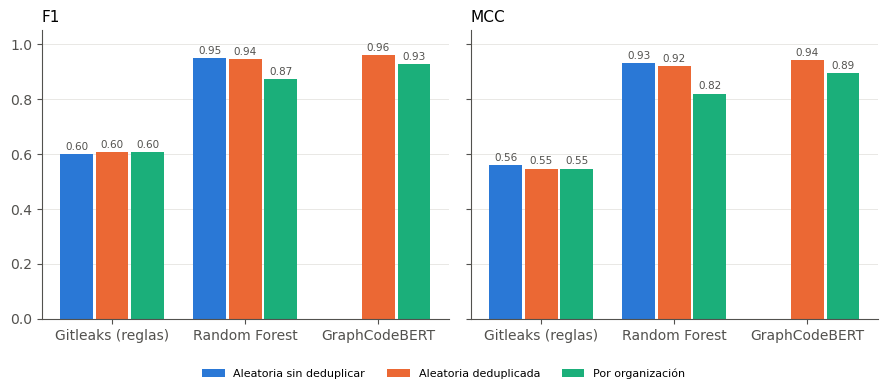

In [9]:
COL = {"Aleatoria sin deduplicar": "#2a78d6", "Aleatoria deduplicada": "#eb6834",
       "Por organización": "#1baf7a", "Por tipo de archivo": "#eda100"}
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b",
                     "xtick.color": "#52514e", "ytick.color": "#52514e"})

fig, axes = plt.subplots(1, 2, figsize=(9, 3.9), sharey=True)
for ax, met, titulo in zip(axes, ["f1", "mcc"], ["F1", "MCC"]):
    dets = list(dict.fromkeys(tabla_global.detector))
    parts = [x for x in COL if x in set(tabla_global.particion)]
    ancho = 0.8 / len(parts)
    for j, part in enumerate(parts):
        vals = [tabla_global.query("detector == @dd and particion == @part")[met].squeeze()
                if len(tabla_global.query("detector == @dd and particion == @part")) else np.nan for dd in dets]
        xs = np.arange(len(dets)) + (j - (len(parts) - 1) / 2) * ancho
        ax.bar(xs, vals, width=ancho * 0.92, color=COL[part], label=part)
        for x, v in zip(xs, vals):
            if not np.isnan(v):
                ax.text(x, v + 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=7.5, color="#52514e")
    ax.set_xticks(np.arange(len(dets)), dets)
    ax.set_title(titulo, loc="left", fontsize=11)
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.6)
    ax.set_axisbelow(True)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=8, loc="lower center", ncol=len(labels))
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(FIG / "fig1_desempeno_global.png", dpi=200)
plt.show()

**Qué salió.** En los dos modelos, la barra de organización no vista queda por debajo de la aleatoria,
tanto en F1 como en MCC, y la diferencia es mayor en Random Forest. Las barras de Gitleaks son
iguales en todas las particiones porque no se entrena.

### 7.2 Tipos de archivo no vistos

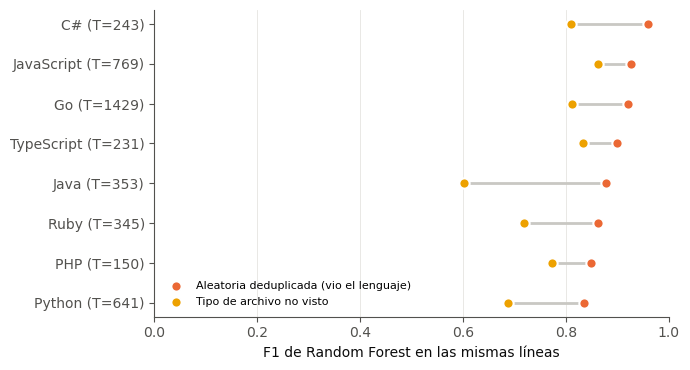

In [10]:
if "f1_rf_tipo" in tabla_tipo:
    tt = tabla_tipo.sort_values("f1_rf_aleatorio")
    fig, ax = plt.subplots(figsize=(7, 3.8))
    yy = np.arange(len(tt))
    ax.hlines(yy, tt.f1_rf_tipo, tt.f1_rf_aleatorio, color="#c9c8c3", linewidth=2)
    ax.scatter(tt.f1_rf_aleatorio, yy, s=55, color=COL["Aleatoria deduplicada"], zorder=3,
               label="Aleatoria deduplicada (vio el lenguaje)", edgecolor="white", linewidth=1.5)
    ax.scatter(tt.f1_rf_tipo, yy, s=55, color=COL["Por tipo de archivo"], zorder=3,
               label="Tipo de archivo no visto", edgecolor="white", linewidth=1.5)
    ax.set_yticks(yy, [f"{a} (T={b})" for a, b in zip(tt.lenguaje, tt.positivos)])
    ax.set_xlabel("F1 de Random Forest en las mismas líneas")
    ax.set_xlim(0, 1)
    ax.grid(axis="x", color="#e5e4e0", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, fontsize=8, loc="lower left")
    fig.tight_layout()
    fig.savefig(FIG / "fig2_tipo_archivo.png", dpi=200)
    plt.show()

**Qué salió.** Todos los puntos de "tipo de archivo no visto" quedan a la izquierda de los de la partición
aleatoria. Java (−0.275), C# (−0.152), Python (−0.148) y Ruby (−0.144) son los que más caen;
JavaScript (−0.064), TypeScript (−0.067) y PHP (−0.075), los que menos.

### 7.3 Pliegues de la partición por organización

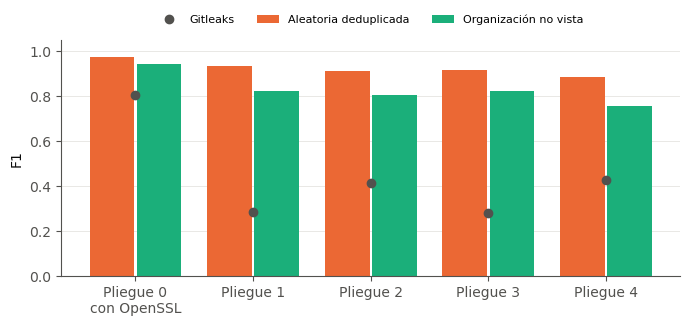

In [11]:
tp = tabla_pliegues
fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(len(tp))
ax.bar(x - 0.2, tp.f1_rf_aleatorio, width=0.38, color=COL["Aleatoria deduplicada"], label="Aleatoria deduplicada")
ax.bar(x + 0.2, tp.f1_rf_organizacion, width=0.38, color=COL["Por organización"], label="Organización no vista")
ax.plot(x, tp.f1_gitleaks, "o", color="#52514e", label="Gitleaks", markersize=6)
ax.set_xticks(x, [f"Pliegue {k}\n{'con OpenSSL' if o else ''}" for k, o in zip(tp.pliegue, tp.contiene_openssl)])
ax.set_ylabel("F1")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", color="#e5e4e0", linewidth=0.6)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.15))
fig.tight_layout()
fig.savefig(FIG / "fig3_pliegues_organizacion.png", dpi=200)
plt.show()

**Qué salió.** La caída aparece en los cinco pliegues, no solo en el promedio. El pliegue 0 (con OpenSSL)
es el más alto para los tres detectores.

## 8. CSV de muestra para compartir (sin texto de código)

1,000 líneas del conjunto deduplicado, estratificadas por etiqueta y partición por
organización, con las variables derivadas, los pliegues, los rasgos de Random Forest y las
predicciones de los tres detectores. No incluye el texto de la línea, por la licencia de cada
proyecto.

In [12]:
rasgos = pd.read_parquet(DATOS / "rasgos_manuales.parquet")
muestra = pd.concat([g.sample(n=min(len(g), 100), random_state=42)
                     for _, g in d.groupby(["y_dedup", "pliegue_organizacion"])])
muestra = muestra.merge(rasgos, on="id_linea", how="left")
cols = (["id_linea", "Id", "FileID", "RepoName", "organizacion", "FilePath", "LineStart", "LineEnd",
         "GroundTruth", "Category", "carpeta", "es_test", "extension", "tipo_archivo", "y_dedup",
         "pliegue_aleatorio", "pliegue_organizacion", "pliegue_tipo", "pred_gitleaks"]
        + [c for c in muestra.columns if c.startswith(("score_rf_", "pred_rf_", "score_gcb_", "pred_gcb_"))
           and "crudo" not in c]
        + list(rasgos.columns.drop("id_linea")))
muestra[cols].sort_values("id_linea").to_csv(RES / "credata_muestra_actividad05.csv", index=False)
print(muestra.shape, muestra.y_dedup.mean())

(1000, 68) 0.5


**Qué salió.** La muestra tiene 1,000 líneas y 63 columnas, con 50% de T por construcción (100 T y 100 no
T por pliegue). Incluye las predicciones de los tres detectores y no incluye el texto de la línea.

## 9. Conclusiones preliminares

- **H₁a recibe apoyo en los dos modelos.** Con organizaciones no vistas, Random Forest baja F1 0.072
  [−0.121, −0.044] y GraphCodeBERT 0.033 [−0.045, −0.020]. En los dos casos el intervalo queda
  completo por debajo de cero, y la caída aparece en los cinco pliegues y en los cuatro análisis de
  sensibilidad.
- **Los dos modelos fallan de forma distinta.** Random Forest deja pasar más credenciales (fuga de
  6.8% a 16.0%). GraphCodeBERT casi no aumenta la fuga (1.4% a 3.2%), pero pierde precisión: genera
  más falsas alarmas.
- **H₁b recibe apoyo para Random Forest**, con una caída mayor (F1 −0.118; recall −0.181) presente
  en los ocho lenguajes. Esta partición también deja fuera la mayoría de los repositorios de cada
  lenguaje, así que la caída no se puede atribuir solo al lenguaje. GraphCodeBERT todavía no tiene
  esta partición.
- **Deduplicar por texto exacto casi no cambia el resultado**, porque la deduplicación quita sobre
  todo negativos (15,093 de 15,168 líneas). La sobrestimación viene de lo que comparten las líneas
  de un mismo proyecto, no de líneas idénticas.
- **La fuga se concentra en credenciales que dependen del contexto del proyecto**, como Password, URL
  Credentials o Auth. Las de formato reconocible casi no cambian. Las cifras de categorías dominadas
  por una organización son inestables.
- **GraphCodeBERT es preliminar**: modo rápido (20,000 líneas, 1 época) con dos defectos de entrada ya
  corregidos para la corrida completa (ver notebook 03).